# **DISTIL Usage Example: Twitter**

Here, we show how to use DISTIL to perform active learning on sentiment analysis tasks using a BERT model with the Twitter Eval sentiment dataset. This notebook can be easily executed on Google Colab.

## Installation and Imports

In [1]:

# Standard imports
import os
import sys
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F

import string
import unicodedata
import math

# Imports for datasets
from datasets import load_dataset, concatenate_datasets
from torch.utils.data import DataLoader, TensorDataset, Dataset, Subset, ConcatDataset
from collections import Counter
from tqdm.auto import tqdm

# Imports for active learning
sys.path.append('distil/')
from distil.active_learning_strategies import BADGE, EntropySampling, LeastConfidenceSampling, MarginSampling, RandomSampling   # All active learning strategies showcased in this example
from distil.utils.utils import LabeledToUnlabeledDataset                       # A utility wrapper class that removes labels from labeled PyTorch dataset objects

/home/ubuntu/.local/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Preparing TREC_eval

tweet_eval is a dataset from Hugging Face that is used for sentiment analysis/sentiment classification. The dataset consists of 59899 English tweets from Twitter users and is split into 3 splits for training (45615), validation (2000), and testing (12284). The labels are as follows: 0 = negative, 1 = neutral, 2 = positive. The dataset can be found here: https://huggingface.co/datasets/tweet_eval

Here, we preprocess each data instance (a tweet) by making all words lowercase, removing punctuation, converting to ASCII format, and removing stopwords. Stopwords are commonly used words in the English language that usually do not provide any useful information for sentiment classification.

In [2]:


dataset = load_dataset("CogComp/trec")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


## Tokenization and Pre-Active Learning

Now that the text has been pre-processed, tokenization of each instance can be performed to produce usable input for BERT. Here, we tokenize the pre-processed tweets using the Huggingface transformers package. We leverage the AutoTokenizer module with the bert-base-uncased configuration to do so. We then make sure that the dataset objects return PyTorch tensors by setting the format as "torch." 

Next, to create an active learning instance, we separate separate the training dataset into an initial labeled subset and an initial unlabeled pool. We also define the number of active learning rounds to perform and the active learning budget for each round.

In [3]:
from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel
from datasets import load_dataset
from torch.utils.data import Subset
import numpy as np

# Load the TREC dataset
dataset = load_dataset("CogComp/trec")
training_data = dataset["train"]
testing_data = dataset["test"]

# Configure model
configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 6)  # TREC has 6 coarse classes

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Tokenize and format dataset
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns(["text", "fine_label"])
test2 = test1.remove_columns(["text", "fine_label"])
training_dataset = train2.rename_column("coarse_label", "labels")
testing_dataset = test2.rename_column("coarse_label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Active learning setup
nclasses = 6
n_rounds = 6
budget = 25
train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

np.random.seed(42)

# Generate splits
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = [i for i in range(len(training_dataset)) if training_dataset[i]["labels"].item() == class_num]
    test_idx_pool = [i for i in range(len(testing_dataset)) if testing_dataset[i]["labels"].item() == class_num]

    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")

    # Sampling subsets
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc).tolist()

    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)

# Create data subsets
trec_train     = Subset(training_dataset, full_train_subset)
trec_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

# Print label distributions
label_count = {i: 0 for i in range(nclasses)}
for i in range(len(trec_train)):
    label_count[trec_train[i]["labels"].item()] += 1
print("Train class distribution:", label_count)

label_count = {i: 0 for i in range(nclasses)}
for i in range(len(testing_dataset)):
    label_count[testing_dataset[i]["labels"].item()] += 1
print("Test class distribution:", label_count)


2025-06-27 11:53:21.329641: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-06-27 11:53:21.375697: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-06-27 11:53:22.272951: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF-TRT Warning: Could not find TensorRT


Class 0 - Training pool size: 86, Testing pool size: 9
Class 1 - Training pool size: 1250, Testing pool size: 94
Class 2 - Training pool size: 1162, Testing pool size: 138
Class 3 - Training pool size: 1223, Testing pool size: 65
Class 4 - Training pool size: 835, Testing pool size: 81
Class 5 - Training pool size: 896, Testing pool size: 113
Train class distribution: {0: 200, 1: 200, 2: 200, 3: 200, 4: 200, 5: 200}
Test class distribution: {0: 1000, 1: 1000, 2: 1000, 3: 1000, 4: 1000, 5: 1000}


## Preparing the Model

The model here is a CustomBERTModel based on https://arxiv.org/abs/1810.04805 and https://arxiv.org/abs/1908.08962. It uses a bidirectional tranformer scheme that has been pretrained based on masked language modeling and next sentence prediction. The model we use is a tailored version of BERT-small from HuggingFace's transformers library that can be found here: https://huggingface.co/prajjwal1/bert-small. The additions allow for sentiment classification and for usage of DISTIL's strategies.

In [4]:
from transformers import BertModel

class CustomBERTModel(nn.Module):
    def __init__(self, config):
        super(CustomBERTModel, self).__init__()
        self.config = config
        self.bert = BertModel.from_pretrained("prajjwal1/bert-small")
        classifier_dropout = (config.classifier_dropout if config.classifier_dropout is not None else config.hidden_dropout_prob)
        self.dropout = nn.Dropout(classifier_dropout)
        self.linear1 = nn.Linear(512,config.num_classes)
        
    def get_embedding_dim(self):
        return 512

    def forward(self, input_ids=None,
               attention_mask=None,
               token_type_ids=None,
               position_ids=None,
               head_mask=None,
               inputs_embeds=None,
               labels=None,
               output_attentions=None,
               output_hidden_states=None,
               return_dict=None, freeze=False, last=False):
        return_dict = return_dict if return_dict is not None else self.config.use_return_dict
        if freeze:
            with torch.no_grad():
                outputs = self.bert(input_ids,
                                    attention_mask=attention_mask,
                                    token_type_ids=token_type_ids,
                                    position_ids=position_ids,
                                    head_mask=head_mask,
                                    inputs_embeds=inputs_embeds,
                                    output_attentions=output_attentions,
                                    output_hidden_states=output_hidden_states,
                                    return_dict=return_dict)
                pooled_output = self.dropout(outputs["pooler_output"])
        else:
            outputs = self.bert(input_ids,
                                attention_mask=attention_mask,
                                token_type_ids=token_type_ids,
                                position_ids=position_ids,
                                head_mask=head_mask,
                                inputs_embeds=inputs_embeds,
                                output_attentions=output_attentions,
                                output_hidden_states=output_hidden_states,
                                return_dict=return_dict)
            pooled_output = self.dropout(outputs["pooler_output"])
        linear1_output = self.linear1(pooled_output)
        if last:
            return linear1_output, pooled_output
        else:
            return linear1_output

base_dir = "models"
os.makedirs(base_dir, exist_ok = True)
model_directory = os.path.join(base_dir, 'base_model.pth')

model = CustomBERTModel(configuration)
if(torch.cuda.is_available()):
    device = "cuda"
else:
    device = "cpu"
model.to(device)

CustomBERTModel(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 512, padding_idx=0)
      (position_embeddings): Embedding(512, 512)
      (token_type_embeddings): Embedding(2, 512)
      (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-3): 4 x BertLayer(
          (attention): BertAttention(
            (self): BertSdpaSelfAttention(
              (query): Linear(in_features=512, out_features=512, bias=True)
              (key): Linear(in_features=512, out_features=512, bias=True)
              (value): Linear(in_features=512, out_features=512, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=512, out_features=512, bias=True)
              (LayerNorm): LayerNorm((512,), eps=1e-12, elementwise

## data_train Class

Here, we define a training procedure that will help us fine-tune the BERT model. Specifically, this data_train class is modeled after the data_train class already included in distil/distil/active_learning_stratgies. However, the following data_train class is designed to work with the dataset format of twitter_eval and the CustomBERTModel.

In [5]:
#custom training
class data_train:
    
    def __init__(self, training_dataset, net, args):

        self.training_dataset = training_dataset
        self.net = net
        self.args = args
        
        self.n_pool = len(training_dataset)
        
        if 'islogs' not in args:
            self.args['islogs'] = False

        if 'optimizer' not in args:
            self.args['optimizer'] = 'adam'
        
        if 'isverbose' not in args:
            self.args['isverbose'] = False
        
        if 'isreset' not in args:
            self.args['isreset'] = True

        if 'n_epoch' not in args:
            self.args['n_epoch'] = 200
            
        if 'criterion' not in args:
            self.args['criterion'] = nn.CrossEntropyLoss()
            
        if 'device' not in args:
            self.device = "cuda" if torch.cuda.is_available() else "cpu"
        else:
            self.device = args['device']

    def update_index(self, idxs_lb):
        self.idxs_lb = idxs_lb

    def update_data(self, new_training_dataset):
        """
        Updates the training dataset with the provided new training dataset
        
        Parameters
        ----------
        new_training_dataset: torch.utils.data.Dataset
            The new training dataset
        """
        self.training_dataset = new_training_dataset

    def get_acc_on_set(self, test_dataset):
        
        """
        Calculates and returns the accuracy on the given dataset to test
        
        Parameters
        ----------
        test_dataset: torch.utils.data.Dataset
            The dataset to test
        Returns
        -------
        accFinal: float
            The fraction of data points whose predictions by the current model match their targets
        """	
        
        try:
            self.clf
        except:
            self.clf = self.net

        if test_dataset is None:
            raise ValueError("Test data not present")
        
        if 'batch_size' in self.args:
            batch_size = self.args['batch_size']
        else:
            batch_size = 1 
 
        loader_te = DataLoader(test_dataset, shuffle=False, batch_size=batch_size)
        self.clf.eval()
        accFinal = 0.

        self.clf = self.clf.to(device=self.device)
        for batch in loader_te:  
            batch = {k: v.to(self.device) for k, v in batch.items()}
            with torch.no_grad():
              out = self.clf(**batch)
              accFinal += torch.sum(1.0*(torch.max(out,1)[1] == batch['labels'].view(-1))).item()

        return accFinal / len(test_dataset)

    def _train(self, epoch, loader_tr, optimizer):
        self.clf.train()
        accFinal = 0.
        criterion = self.args['criterion']
        criterion.reduction = "mean"

        for batch in loader_tr:
            batch = {k: v.to(self.device) for k, v in batch.items()}
            out = self.clf(**batch, freeze=True)
            loss = criterion(out, batch['labels'].view(-1))
            accFinal += torch.sum((torch.max(out,1)[1] == batch['labels'].view(-1)).float()).item()
            loss.backward()

            optimizer.step()
            optimizer.zero_grad()

        return accFinal / len(loader_tr.dataset), loss

    def train(self, gradient_weights=None):

        print('Training..')
        train_logs = []
        
        try:
            self.clf
        except:
            self.clf = self.net
        
        if self.args['isreset']:
            self.clf.linear1.reset_parameters()
        
        if 'batch_size' in self.args:
            batch_size = self.args['batch_size']
        else:
            batch_size = 1

        loader_tr = DataLoader(self.training_dataset, shuffle=True, batch_size=batch_size)
        epoch = 1
        accCurrent = 0

        if self.args['optimizer'] == 'adam':
            optimizer = AdamW(self.clf.parameters(), lr = self.args['lr'])

        while epoch < self.args['n_epoch']: 
            self.clf = self.clf.to(device=self.device)
            accCurrent, lossCurrent = self._train(epoch, loader_tr, optimizer)
            
            epoch += 1
            if epoch % 5 == 0:
                print(str(epoch) + ' training accuracy: ' + str(accCurrent), flush=True)

            log_string = 'Epoch:' + str(epoch) + '- training accuracy:'+str(accCurrent)+'- training loss:'+str(lossCurrent)
            train_logs.append(log_string)

        print('Epoch:', str(epoch), 'Training accuracy:', round(accCurrent, 3), flush=True)

        if self.args['islogs']:
            return self.clf, train_logs
        else:
            return self.clf

## Training an Initial Model

Now that our model, labeled data, and unlabeled data are prepared, we can now train an initial model. Here, we use AdamW with a learning rate of 1e-4 and batch size of 5 for 200 epochs.

In [6]:
args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'} 
dt = data_train(trec_train, model, args)
clf = dt.train()
torch.save(clf.state_dict(), model_directory)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Training..


/home/ubuntu/.local/lib/python3.8/site-packages/transformers/optimization.py:591: FutureWarning: This implementation of AdamW is deprecated and will be removed in a future version. Use the PyTorch implementation torch.optim.AdamW instead, or set `no_deprecation_warning=True` to disable this warning
  warnings.warn(


5 training accuracy: 0.38166666666666665
10 training accuracy: 0.5008333333333334
15 training accuracy: 0.5558333333333333
20 training accuracy: 0.5858333333333333
25 training accuracy: 0.6166666666666667
30 training accuracy: 0.6125
35 training accuracy: 0.6216666666666667
40 training accuracy: 0.6483333333333333
45 training accuracy: 0.655
50 training accuracy: 0.6541666666666667
55 training accuracy: 0.6591666666666667
60 training accuracy: 0.6641666666666667
65 training accuracy: 0.6791666666666667
70 training accuracy: 0.6833333333333333
75 training accuracy: 0.6691666666666667
80 training accuracy: 0.665
85 training accuracy: 0.6808333333333333
90 training accuracy: 0.6808333333333333
95 training accuracy: 0.685
100 training accuracy: 0.6775
105 training accuracy: 0.69
110 training accuracy: 0.69
115 training accuracy: 0.685
120 training accuracy: 0.7025
125 training accuracy: 0.6941666666666667
130 training accuracy: 0.7025
135 training accuracy: 0.69
140 training accuracy: 0.68

/tmp/ipykernel_79095/4293823040.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

## Active Learning Strategies

Now that we have the initial model, we can use one of DISTIL's active learning strategies to select examples from twitter_eval to label and to use in future training.

### Random Sampling
This strategy is often used as a baseline, where we pick a subset of unlabeled points randomly. Here, we create a instance of `distil.active_learning_strategies.random_sampling.RandomSampling` by passing following parameters:

**training_dataset** – The labeled dataset, which has a PyTorch interface that returns a tensor of data and a tensor of labels OR a dictionary with a "labels" key.

**unlabeled_dataset** – The unlabeled dataset, which has a PyTorch interface that returns a tensor of data OR a dictionary.

**net** – Model architecture used for training. Could be instance of models defined in distil.utils.models or something similar (in this instance, a Huggingface transformer).

**nclasses** – No. of classes in the dataset

**args**– This dictionary should have ‘batch_size’ as a key. 'batch_size' should be such that one can exploit the benefits of tensorization while honouring the resourse constraits. This ‘batch_size’ therefore can be different than the one used for training.


In [7]:

from copy import deepcopy

initial_trec_train = deepcopy(trec_train)
initial_unlabeled = deepcopy(trec_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    trec_train = deepcopy(initial_trec_train)
    dt = data_train(trec_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    trec_unlabeled = deepcopy(initial_unlabeled)
    strategy = RandomSampling(trec_train, LabeledToUnlabeledDataset(trec_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(trec_unlabeled, idx)
        trec_train = ConcatDataset([trec_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(trec_unlabeled))) - set(idx))
        trec_unlabeled = Subset(trec_unlabeled, remaining_indices)

        print("Number of training samples:", len(trec_train))

        # Update strategy and training data
        strategy.update_data(trec_train, LabeledToUnlabeledDataset(trec_unlabeled))
        dt.update_data(trec_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'trec', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_random.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_79095/2223622634.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 100.0%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1225
Training..
5 training accuracy: 0.4236734693877551
10 training accuracy: 0.5126530612244898
15 training accuracy: 0.5730612244897959
20 training accuracy: 0.593469387755102
25 training accuracy: 0.6065306122448979
30 training accuracy: 0.6261224489795918
35 training accuracy: 0.6481632653061224
40 training accuracy: 0.6416326530612245
45 training accuracy: 0.6408163265306123
50 training accuracy: 0.6555102040816326
55 training accuracy: 0.6604081632653062
60 training accuracy: 0.6653061224489796
65 training accuracy: 0.6685714285714286
70 training accuracy: 0.673469387755102
75 training accuracy: 0.676734693877551
80 training accuracy: 0.6857142857142857
85 training accuracy: 0.6914285714285714
90 training accuracy: 0.6628571428571428
95 training accuracy: 0.7004081632653061
100 training accurac

### Entropy Sampling
A very basic strategy to select unlabeled points is entropy sampling, where we select samples about which the model is most uncertain by measuring the entropy of the class prediction. Hence, a valid strategy is to select those points in the unlabeled set with highest entropy (maximum uncertainty). Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Using the softmax probabilities, entropy sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ -\sum_j \sigma(z)_j*\log(\sigma(z)_j) \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.EntropySampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [8]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in trec dataset
nclasses = 6
n_rounds = 6
budget = 25

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
trec_train     = Subset(training_dataset, full_train_subset)
trec_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900
Class 4 - Training pool size: 0, Testing pool size: 0


ValueError: 'a' cannot be empty unless no samples are taken

In [ ]:

from copy import deepcopy
from distil.utils.utils import LabeledToUnlabeledDataset  

initial_trec_train = deepcopy(trec_train)
initial_unlabeled = deepcopy(trec_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    trec_train = deepcopy(initial_trec_train)
    dt = data_train(trec_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    trec_unlabeled = deepcopy(initial_unlabeled)
    strategy = EntropySampling(trec_train, LabeledToUnlabeledDataset(trec_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(trec_unlabeled, idx)
        trec_train = ConcatDataset([trec_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(trec_unlabeled))) - set(idx))
        trec_unlabeled = Subset(trec_unlabeled, remaining_indices)

        print("Number of training samples:", len(trec_train))

        # Update strategy and training data
        strategy.update_data(trec_train, LabeledToUnlabeledDataset(trec_unlabeled))
        dt.update_data(trec_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'trec', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_entropy.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/4126878991.py:17: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)
Error during conversion: ChunkedEncodingError(P

Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6045454545454545
10 training accuracy: 0.6754545454545454
15 training accuracy: 0.6881818181818182
20 training accuracy: 0.7290909090909091
25 training accuracy: 0.7318181818181818
30 training accuracy: 0.7354545454545455
35 training accuracy: 0.7390909090909091
40 training accuracy: 0.7363636363636363
45 training accuracy: 0.7318181818181818
50 training accuracy: 0.7563636363636363
55 training accuracy: 0.76
60 training accuracy: 0.7536363636363637
65 training accuracy: 0.7545454545454545
70 training accuracy: 0.76
75 training accuracy: 0.7563636363636363
80 training accuracy: 0.7572727272727273
85 training accuracy: 0.7672727272727272
90 training accuracy: 0.7609090909090909
95 training accuracy: 0.7681818181818182
100 training accuracy: 0.7781818181818182
105 

### BADGE
This method is based on the paper [Deep Batch Active Learning by Diverse, Uncertain Gradient Lower Bounds](https://arxiv.org/abs/1906.03671). The strategy is meant to select points that are both diverse (e.g., their embeddings span multiple directions) and uncertain (e.g., their contribution to the loss is large). The following steps are taken:

* Calculate the pseudo-label for each point in the unlabeled set. The pseudo-label is the class with the highest probability.
* Compute the cross-entropy loss for each point in the unlabeled set using this pseudo-label.
* Obtain the resulting loss gradients on the last linear layer of the model for each point. (These are referred to as the hypothesized loss gradients.)
* Using these gradients as a form of embedding for each unlabeled point, run k-means++ initialization on this embedding set, retrieving $k$ centers. Each center is a point from the unlabeled set, and $k$ represents the active learning budget.
* Request labels for the $k$ points whose embeddings were selected.

Here we create a instance of `distil.active_learning_strategies.badge.BADGE` with same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [ ]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in trec dataset
nclasses = 6
n_rounds = 6
budget = 25

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
trec_train     = Subset(training_dataset, full_train_subset)
trec_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_67934/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [ ]:

from copy import deepcopy

initial_trec_train = deepcopy(trec_train)
initial_unlabeled = deepcopy(trec_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    trec_train = deepcopy(initial_trec_train)
    dt = data_train(trec_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    trec_unlabeled = deepcopy(initial_unlabeled)
    strategy = BADGE(trec_train, LabeledToUnlabeledDataset(trec_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(trec_unlabeled, idx)
        trec_train = ConcatDataset([trec_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(trec_unlabeled))) - set(idx))
        trec_unlabeled = Subset(trec_unlabeled, remaining_indices)

        print("Number of training samples:", len(trec_train))

        # Update strategy and training data
        strategy.update_data(trec_train, LabeledToUnlabeledDataset(trec_unlabeled))
        dt.update_data(trec_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'trec', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_badge.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/961531629.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6745454545454546
10 training accuracy: 0.7345454545454545
15 training accuracy: 0.7636363636363637
20 training accuracy: 0.7645454545454545
25 training accuracy: 0.7918181818181819
30 training accuracy: 0.7936363636363636
35 training accuracy: 0.7854545454545454
40 training accuracy: 0.8018181818181818
45 training accuracy: 0.7809090909090909
50 training accuracy: 0.8036363636363636
55 training accuracy: 0.81
60 training accuracy: 0.8072727272727273
65 training accuracy: 0.81
70 training accuracy: 0.8136363636363636
75 training accuracy: 0.8181818181818182
80 training accuracy: 0.8118181818181818
85 training accuracy: 0.8136363636363636
90 training accuracy: 0.8218181818181818
95 training accuracy: 0.8263636363636364
100 training accuracy: 0.8236363636363636
105 

### Least Confidence Sampling

A very basic strategy to select unlabeled points is least confidence sampling, where we select samples about which the model is most uncertain by measuring the confidence of the class prediction. Hence, a valid strategy is to select those points in the unlabeled set with the least confident predictions (lowest maximum probability score). Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Using the softmax probabilities, entropy sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ \max_j \sigma(z)_j \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.LeastConfidenceSampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [ ]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in trec dataset
nclasses = 6
n_rounds = 6
budget = 25

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
trec_train     = Subset(training_dataset, full_train_subset)
trec_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_67934/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


In [ ]:

from copy import deepcopy

initial_trec_train = deepcopy(trec_train)
initial_unlabeled = deepcopy(trec_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict, strict=False)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    trec_train = deepcopy(initial_trec_train)
    dt = data_train(trec_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    trec_unlabeled = deepcopy(initial_unlabeled)
    strategy = LeastConfidenceSampling(trec_train, LabeledToUnlabeledDataset(trec_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(trec_unlabeled, idx)
        trec_train = ConcatDataset([trec_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(trec_unlabeled))) - set(idx))
        trec_unlabeled = Subset(trec_unlabeled, remaining_indices)

        print("Number of training samples:", len(trec_train))

        # Update strategy and training data
        strategy.update_data(trec_train, LabeledToUnlabeledDataset(trec_unlabeled))
        dt.update_data(trec_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'trec', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_leastConfidence.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/3811793927.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6363636363636364
10 training accuracy: 0.6863636363636364
15 training accuracy: 0.7072727272727273
20 training accuracy: 0.7109090909090909
25 training accuracy: 0.7163636363636363
30 training accuracy: 0.75
35 training accuracy: 0.7254545454545455
40 training accuracy: 0.7381818181818182
45 training accuracy: 0.7454545454545455
50 training accuracy: 0.74
55 training accuracy: 0.7745454545454545
60 training accuracy: 0.7609090909090909
65 training accuracy: 0.7563636363636363
70 training accuracy: 0.7645454545454545
75 training accuracy: 0.77
80 training accuracy: 0.7618181818181818
85 training accuracy: 0.7727272727272727
90 training accuracy: 0.7790909090909091
95 training accuracy: 0.7727272727272727
100 training accuracy: 0.7645454545454545
105 training accur

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 1: 94.2%
-------------------------------------------------
Round 1 for class 1
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.5945454545454546
10 training accuracy: 0.6718181818181819
15 training accuracy: 0.7
20 training accuracy: 0.7209090909090909
25 training accuracy: 0.7081818181818181
30 training accuracy: 0.7163636363636363
35 training accuracy: 0.7327272727272728
40 training accuracy: 0.7390909090909091
45 training accuracy: 0.74
50 training accuracy: 0.7327272727272728
55 training accuracy: 0.7536363636363637
60 training accuracy: 0.7481818181818182
65 training accuracy: 0.76
70 training accuracy: 0.7481818181818182
75 training accuracy: 0.7736363636363637
80 training accuracy: 0.7745454545454545
85 training accuracy: 0.7781818181818182
90 training accuracy: 0.7672727272727272
95 training accuracy: 0.7681818181818182
100 training accuracy: 0.78
105 training accuracy: 0.78272727

Error during conversion: ChunkedEncodingError(ProtocolError('Response ended prematurely'))


Initial test accuracy on class 3: 76.5%
-------------------------------------------------
Round 1 for class 3
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6263636363636363
10 training accuracy: 0.7
15 training accuracy: 0.72
20 training accuracy: 0.73
25 training accuracy: 0.7154545454545455
30 training accuracy: 0.7418181818181818
35 training accuracy: 0.730909090909091
40 training accuracy: 0.7509090909090909
45 training accuracy: 0.7454545454545455
50 training accuracy: 0.7490909090909091
55 training accuracy: 0.7536363636363637
60 training accuracy: 0.7618181818181818
65 training accuracy: 0.7527272727272727
70 training accuracy: 0.7627272727272727
75 training accuracy: 0.7627272727272727
80 training accuracy: 0.7654545454545455
85 training accuracy: 0.7781818181818182
90 training accuracy: 0.7663636363636364
95 training accuracy: 0.7654545454545455
100 training accuracy: 0.769090909090909
105 training accuracy

### Margin Sampling

A very basic strategy to select unlabeled points is margin sampling, where we select samples about which the model is most uncertain by measuring the difference between the probability of the most confident class and the probability of the second-most confident class. Hence, a valid strategy is to select those points in the unlabeled set with the smallest margin of prediction. Specifically, let $z = f(x)$ be the output from the model with class $i$ having score $z_i$. By applying a softmax, we obtain probabilities that we can use: 

$$\sigma(z)_i = \frac{e^{z_i}}{\sum_j e^{z_j}}$$ 

Defining

$$\lambda_1 = \text{argmax}_i \sigma(z)_i$$

and

$$\lambda_2 = \text{argmax}_{i \neq \lambda_1} \sigma(z)_i,$$

margin sampling selects a subset based on the following objective:

 $$\text{argmin}_{A \subseteq U, |A| = k} \sum_{x \in A} \left[ \sigma(z)_{\lambda_1} - \sigma(z)_{\lambda_2} \right]$$

Here, we create a instance of `distil.active_learning_strategies.entropy_sampling.MarginSampling` with the same parameters passed to `distil.active_learning_strategies.random_sampling.RandomSampling`.

**Reload Data**

Here we reload, reprocess, and retokenize the data and prepare for a different active learning strategy.

In [ ]:


dataset = load_dataset("fancyzhx/ag_news")

train_dataset = dataset['train']
test_dataset = dataset['test']

# Text preprocessing functions
def to_lower(ex):
    ex['text'] = ex['text'].lower()
    return ex

def remove_punc(ex):
    ex['text'] = ''.join(x for x in ex['text'] if x not in string.punctuation)
    return ex

def to_ascii(ex):
    ex['text'] = ''.join(x for x in unicodedata.normalize('NFD', ex['text']) if unicodedata.category(x) != 'Mn')
    return ex

stopwords = [ "a", "about", "above", "after", "again", "against", "all", "am", "an", "and", "any", "are", "as", "at", "be", "because", 
             "been", "before", "being", "below", "between", "both", "but", "by", "could", "did", "do", "does", "doing", "down", "during",
             "each", "few", "for", "from", "further", "had", "has", "have", "having", "he", "he'd", "he'll", "he's", "her", "here", 
             "here's", "hers", "herself", "him", "himself", "his", "how", "how's", "i", "i'd", "i'll", "i'm", "i've", "if", "in", "into",
             "is", "it", "it's", "its", "itself", "let's", "me", "more", "most", "my", "myself", "nor", "of", "on", "once", "only", "or",
             "other", "ought", "our", "ours", "ourselves", "out", "over", "own", "same", "she", "she'd", "she'll", "she's", "should", 
             "so", "some", "such", "than", "that", "that's", "the", "their", "theirs", "them", "themselves", "then", "there", "there's",
             "these", "they", "they'd", "they'll", "they're", "they've", "this", "those", "through", "to", "too", "under", "until", "up",
             "very", "was", "we", "we'd", "we'll", "we're", "we've", "were", "what", "what's", "when", "when's", "where", "where's",
             "which", "while", "who", "who's", "whom", "why", "why's", "with", "would", "you", "you'd", "you'll", "you're", "you've",
             "your", "yours", "yourself", "yourselves" ]

def remove_stopwords(ex):
    ex['text'] = ' '.join(x for x in ex['text'].split() if x not in stopwords)
    return ex

def process_data(data):
    data1 = data.map(remove_punc)
    data2 = data1.map(to_ascii)
    data3 = data2.map(to_lower)
    data4 = data3.map(remove_stopwords)
    return data4

# Apply processing
training_data = process_data(train_dataset)
testing_data = process_data(test_dataset)


from transformers import AutoTokenizer, get_scheduler, BertConfig, AdamW, BertModel

configuration = BertConfig()
setattr(configuration, 'l1', 512)
setattr(configuration, 'num_classes', 4)

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

def tokenize_func(ex):
    return tokenizer(ex['text'], padding='max_length', truncation=True)

# Removes unnecessary columns and renames columns to match the model specification
train1 = training_data.map(tokenize_func, batched=True)
test1 = testing_data.map(tokenize_func, batched=True)
train2 = train1.remove_columns("text")
test2 = test1.remove_columns("text")
training_dataset = train2.rename_column("label", "labels")
testing_dataset = test2.rename_column("label", "labels")

training_dataset.set_format("torch")
testing_dataset.set_format("torch")

# Define the number of active learning rounds to conduct, the budget, and the number of classes in trec dataset
nclasses = 6
n_rounds = 6
budget = 25

train_size_pc     = 200
test_size_pc      = 1000
unlabeled_size_pc = 5000

# Ensure reproducibility
np.random.seed(42)

# Generate random index lists for subset creation
full_train_subset = []
full_unlabeled_subset = []
full_test_subset = []

for class_num in range(nclasses):
    train_idx_pool = []
    for train_idx in range(len(training_dataset)):
        if training_dataset[train_idx]["labels"].item() == class_num:
            train_idx_pool.append(train_idx)
    test_idx_pool = []
    for test_idx in range(len(testing_dataset)):
        if testing_dataset[test_idx]["labels"].item() == class_num:
            test_idx_pool.append(test_idx)

    # Get a random subset from each pool
    print(f"Class {class_num} - Training pool size: {len(train_idx_pool)}, Testing pool size: {len(test_idx_pool)}")
    train_idx_subset = np.random.choice(train_idx_pool, size=train_size_pc, replace = False).tolist()
    remaining_idx = list(set(train_idx_pool) - set(train_idx_subset))
    unlabeled_idx_subset = np.random.choice(remaining_idx, size=unlabeled_size_pc, replace = False).tolist()
    test_idx_subset = np.random.choice(test_idx_pool, size=test_size_pc, replace = False).tolist()
    full_train_subset.extend(train_idx_subset)
    full_unlabeled_subset.extend(unlabeled_idx_subset)
    full_test_subset.extend(test_idx_subset)


# Create the splits
trec_train     = Subset(training_dataset, full_train_subset)
trec_unlabeled = Subset(training_dataset, full_unlabeled_subset)
testing_dataset = Subset(testing_dataset, full_test_subset)

model = CustomBERTModel(configuration)
state_dict = torch.load(model_directory)
model.load_state_dict(state_dict)

Class 0 - Training pool size: 30000, Testing pool size: 1900
Class 1 - Training pool size: 30000, Testing pool size: 1900
Class 2 - Training pool size: 30000, Testing pool size: 1900
Class 3 - Training pool size: 30000, Testing pool size: 1900


/tmp/ipykernel_75179/1616557085.py:113: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


<All keys matched successfully>

In [ ]:

from copy import deepcopy

initial_trec_train = deepcopy(trec_train)
initial_unlabeled = deepcopy(trec_unlabeled)
# Loop over each class
for target_class in range(nclasses):
    print(f"\n========= Class {target_class} =========")

    # Restrict test set to only this class
    class_test_indices = [i for i in range(len(testing_dataset)) if testing_dataset[i]['labels'].item() == target_class]
    class_test_set = Subset(testing_dataset, class_test_indices)

    # Reinitialize and load the pretrained model
   
    model = CustomBERTModel(configuration)
    state_dict = torch.load(model_directory)
    model.load_state_dict(state_dict)

    # Set up training args again
    args = {'lr':1e-4, 'batch_size':5, 'n_epoch': 200, 'optimizer':'adam'}
    trec_train = deepcopy(initial_trec_train)
    dt = data_train(trec_train, model, args)

    # Create AL strategy instance
    strategy_args = {'batch_size' : 5}
    trec_unlabeled = deepcopy(initial_unlabeled)
    strategy = MarginSampling(trec_train, LabeledToUnlabeledDataset(trec_unlabeled), model, nclasses, strategy_args)
    strategy.update_model(model)

    # Track accuracy across rounds
    acc = np.zeros(n_rounds)
    acc[0] = dt.get_acc_on_set(class_test_set)
    print(f"Initial test accuracy on class {target_class}: {round(acc[0]*100, 2)}%")

    # Active Learning Loop
    for rd in range(1, n_rounds):
        print('-------------------------------------------------')
        print(f'Round {rd} for class {target_class}')
        print('-------------------------------------------------')

        # Disable augmentation for selection
        idx = strategy.select(budget)

        # Add selected samples to training set
        selected_subset = Subset(trec_unlabeled, idx)
        trec_train = ConcatDataset([trec_train, selected_subset])

        # Update unlabeled pool
        remaining_indices = list(set(range(len(trec_unlabeled))) - set(idx))
        trec_unlabeled = Subset(trec_unlabeled, remaining_indices)

        print("Number of training samples:", len(trec_train))

        # Update strategy and training data
        strategy.update_data(trec_train, LabeledToUnlabeledDataset(trec_unlabeled))
        dt.update_data(trec_train)

        # Retrain model
        clf = dt.train()
        strategy.update_model(clf)

        # Evaluate on current class only
        acc[rd] = dt.get_acc_on_set(class_test_set)
        print(f"Accuracy on class {target_class}: {round(acc[rd]*100, 2)}%")

    print(f"Training completed for class {target_class}")

    # Save accuracy results
    dir = os.path.join('results', 'trec', 'baseline')
    os.makedirs(dir, exist_ok=True)
    save_path = os.path.join(dir, f'class_{target_class}_marginSampling.txt')
    with open(save_path, 'w') as f:
        for a in acc:
            f.write(f"{a}\n")
    print(f"Saved class-wise accuracy to: {save_path}")


========= Class 0 =========


/tmp/ipykernel_67934/3901066692.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  state_dict = torch.load(model_directory)


Initial test accuracy on class 0: 84.5%
-------------------------------------------------
Round 1 for class 0
-------------------------------------------------
Number of training samples: 1100
Training..
5 training accuracy: 0.6527272727272727
10 training accuracy: 0.7190909090909091
15 training accuracy: 0.7327272727272728
20 training accuracy: 0.7536363636363637
25 training accuracy: 0.7372727272727273
30 training accuracy: 0.7518181818181818
35 training accuracy: 0.7772727272727272
40 training accuracy: 0.7527272727272727
45 training accuracy: 0.7745454545454545
50 training accuracy: 0.7827272727272727
55 training accuracy: 0.7745454545454545
60 training accuracy: 0.7645454545454545
65 training accuracy: 0.7781818181818182
70 training accuracy: 0.7772727272727272
75 training accuracy: 0.7836363636363637
80 training accuracy: 0.7927272727272727
85 training accuracy: 0.7881818181818182
90 training accuracy: 0.8072727272727273
95 training accuracy: 0.7845454545454545
100 training accur

Fully Supervised traning

In [ ]:
import os
import torch
import numpy as np
from copy import deepcopy
from torch.utils.data import DataLoader
from torch.nn.functional import softmax

# Reload full training and test datasets (already tokenized & formatted)
full_train_dataset = training_dataset
full_test_dataset = testing_dataset  # already subset, but here we use full testing_data for full evaluation

# Load model and weights
model = deepcopy(CustomBERTModel(configuration))
model.load_state_dict(torch.load(model_directory))

# Training arguments
args = {'n_epoch': 10, 'lr': 2e-5, 'batch_size': 16, 'optimizer': 'adam'}

# Train on full dataset
dt = data_train(full_train_dataset, model, args)
dt.update_data(full_train_dataset)
trained_model = dt.train()

# Evaluate per-class accuracy on full test set
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
trained_model.to(device)
trained_model.eval()

# Reload and preprocess full test set
full_test_dataset = testing_data.map(tokenize_func, batched=True)
full_test_dataset = full_test_dataset.remove_columns("text").rename_column("label", "labels")
full_test_dataset.set_format("torch")
test_loader = DataLoader(full_test_dataset, batch_size=64, shuffle=False)

nclasses = 6
correct_per_class = [0 for _ in range(nclasses)]
total_per_class = [0 for _ in range(nclasses)]

with torch.no_grad():
    for batch in test_loader:
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        outputs = trained_model(input_ids=input_ids, attention_mask=attention_mask)
        logits = outputs.logits if hasattr(outputs, "logits") else outputs
        predictions = torch.argmax(softmax(logits, dim=1), dim=1)

        for i in range(len(labels)):
            label = labels[i].item()
            pred = predictions[i].item()
            total_per_class[label] += 1
            correct_per_class[label] += int(pred == label)

# Compute per-class accuracy
per_class_accuracy = [correct / total if total > 0 else 0.0 for correct, total in zip(correct_per_class, total_per_class)]

# Save results
ref_dir = os.path.join("results", "trec", "baseline")
os.makedirs(ref_dir, exist_ok=True)

for cls, acc in enumerate(per_class_accuracy):
    acc_path = os.path.join(ref_dir, f"class_{cls}_fully_supervised.txt")
    with open(acc_path, "w") as f:
        f.write(str(acc))
    print(f"Saved fully supervised accuracy for class {cls}: {round(acc * 100, 2)}% → {acc_path}")



/tmp/ipykernel_75179/327309749.py:14: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(model_directory))


Training..


## Visualizing the Results

200
Missing file: results/trec/baseline/class_0_entropy.txt
Missing file: results/trec/baseline/class_0_badge.txt
Missing file: results/trec/baseline/class_0_leastConfidence.txt
Missing file: results/trec/baseline/class_0_marginSampling.txt


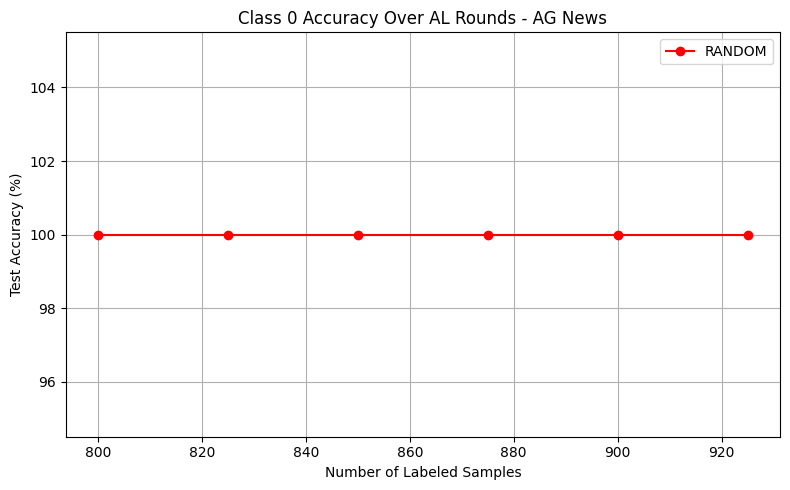

Missing file: results/trec/baseline/class_1_entropy.txt
Missing file: results/trec/baseline/class_1_badge.txt
Missing file: results/trec/baseline/class_1_leastConfidence.txt
Missing file: results/trec/baseline/class_1_marginSampling.txt


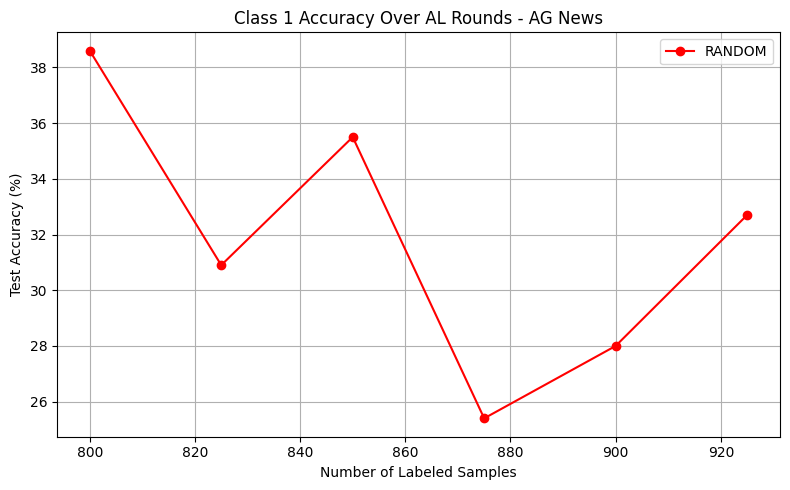

Missing file: results/trec/baseline/class_2_entropy.txt
Missing file: results/trec/baseline/class_2_badge.txt
Missing file: results/trec/baseline/class_2_leastConfidence.txt
Missing file: results/trec/baseline/class_2_marginSampling.txt


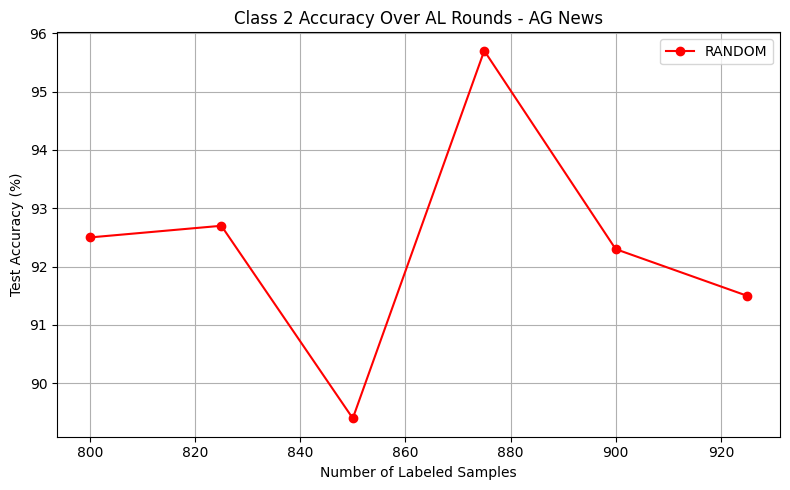

Missing file: results/trec/baseline/class_3_entropy.txt
Missing file: results/trec/baseline/class_3_badge.txt
Missing file: results/trec/baseline/class_3_leastConfidence.txt
Missing file: results/trec/baseline/class_3_marginSampling.txt


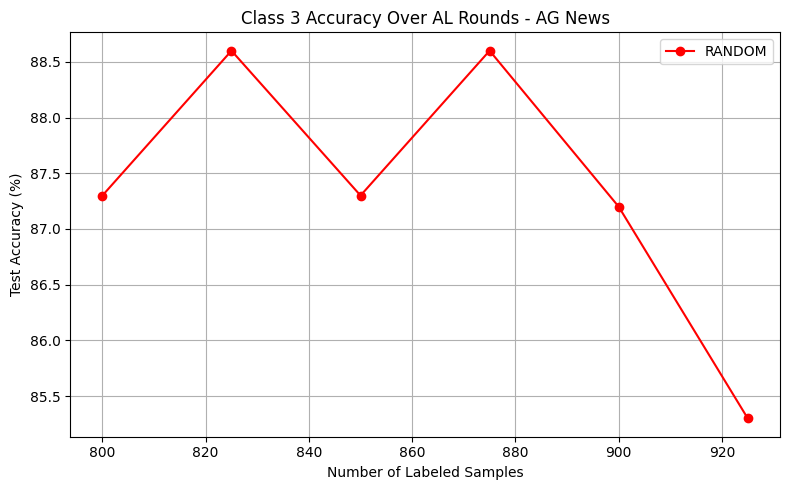

Missing file: results/trec/baseline/class_4_entropy.txt
Missing file: results/trec/baseline/class_4_badge.txt
Missing file: results/trec/baseline/class_4_leastConfidence.txt
Missing file: results/trec/baseline/class_4_marginSampling.txt


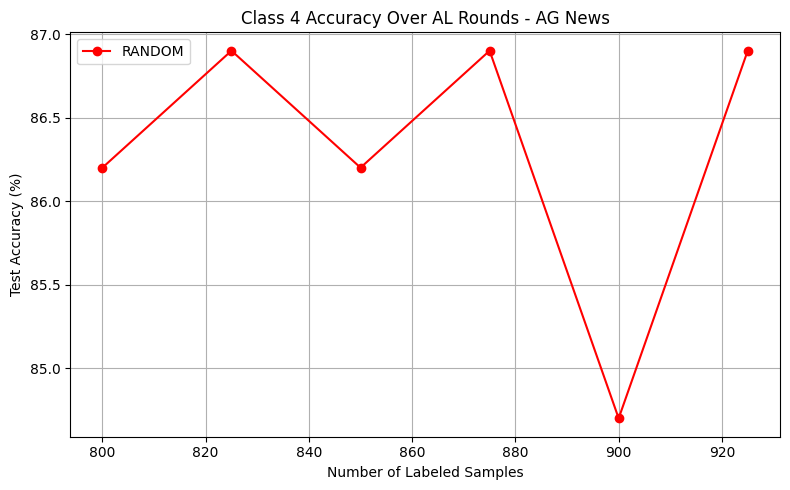

Missing file: results/trec/baseline/class_5_entropy.txt
Missing file: results/trec/baseline/class_5_badge.txt
Missing file: results/trec/baseline/class_5_leastConfidence.txt
Missing file: results/trec/baseline/class_5_marginSampling.txt


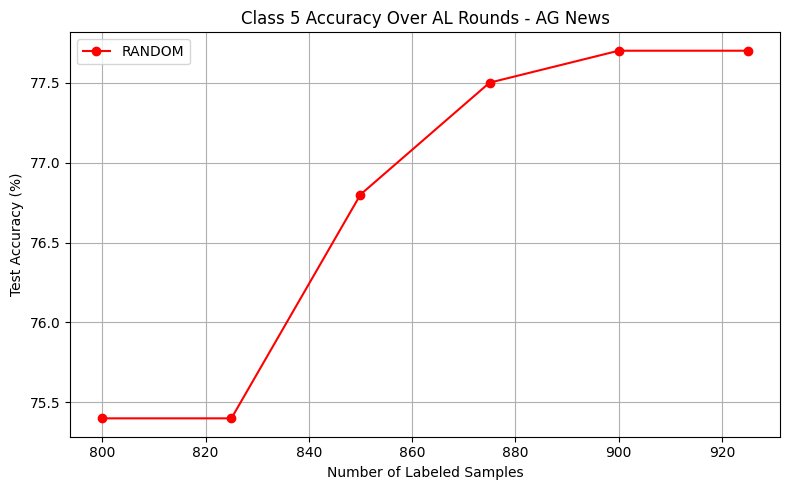

In [9]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Directory with accuracy result files
dir = os.path.join('results', 'trec', 'baseline')

# Define AL experiment parameters
print(train_size_pc)
x_axis = np.array([(train_size_pc * 4) + budget * i for i in range(n_rounds)])

# Strategies to compare
strategies = ['random', 'entropy', 'badge', 'leastConfidence', 'marginSampling']
colors = {
    'random': 'r',
    'entropy': 'g',
    'badge': 'c',
    'glister': 'b',
    'leastConfidence': 'm',
    'marginSampling': 'y'
}
labels = {
    'random': 'RANDOM',
    'entropy': 'UNCERTAINTY',
    'badge': 'BADGE',
    'leastConfidence': 'LEAST CONFIDENCE',
    'marginSampling': 'MARGIN SAMPLING'
}

# Plot per-class accuracy curves
for cls in range(nclasses):
    plt.figure(figsize=(8, 5))

    # Load fully supervised reference
    full_sup_file = os.path.join(dir, f'class_{cls}_fully_supervised.txt')
    if os.path.exists(full_sup_file):
        with open(full_sup_file, 'r') as f:
            ref_acc = round(float(f.read().strip()) * 100, 2)
            plt.axhline(y=ref_acc, color='k', linestyle='--', label='FULLY SUPERVISED')

    for strat in strategies:
        file_path = os.path.join(dir, f'class_{cls}_{strat}.txt')
        if not os.path.exists(file_path):
            print(f"Missing file: {file_path}")
            continue

        with open(file_path, 'r') as f:
            acc_list = [round(float(line.strip()) * 100, 2) for line in f]
            plt.plot(x_axis, acc_list, label=labels[strat], marker='o', color=colors[strat])

    plt.title(f'Class {cls} Accuracy Over AL Rounds - AG News')
    plt.xlabel('Number of Labeled Samples')
    plt.ylabel('Test Accuracy (%)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

